In [1]:
import pandas as pd

# CASP TABLE
df = pd.read_csv("./figs/score.summary.csv")
df = df[df["Dataset"].str.contains("CASP")]
df = df[
    ~((df["Method"] == "DynaHelix") & (df["Metric"] == "Top-5")) & (df["ScoreName"] == "DockQ")
]  # exclude top5 of dynahelix
df = df.sort_values(by=["Method"], ascending=[True])
seed100_df = df[df["Dataset"].str.contains("100")]
# seed5_df = df[~df['Dataset'].str.contains('100')]
print(seed100_df.columns)
seed100_df

Index(['Dataset', 'Method', 'PDB', 'Metric', 'Score', 'ScoreName'], dtype='str')


,Dataset,Method,PDB,Metric,Score,ScoreName
323,CASP 15/16\nNum Of Seed: 100,Boltz-1,H1106,Top-1,0.557754,DockQ
324,CASP 15/16\nNum Of Seed: 100,Boltz-1,H1106,Top-5,0.560331,DockQ
325,CASP 15/16\nNum Of Seed: 100,Boltz-1,H1106,Oracle,0.603745,DockQ
326,CASP 15/16\nNum Of Seed: 100,Boltz-1,H1129,Top-1,0.011669,DockQ
327,CASP 15/16\nNum Of Seed: 100,Boltz-1,H1129,Top-5,0.011669,DockQ
...,...,...,...,...,...,...
641,CASP 15/16\nNum Of Seed: 100,Protenix (BaseConstraint),H1232,Top-5,0.170959,DockQ
642,CASP 15/16\nNum Of Seed: 100,Protenix (BaseConstraint),H1232,Oracle,0.344081,DockQ
643,CASP 15/16\nNum Of Seed: 100,Protenix (BaseConstraint),H1233,Top-1,0.837316,DockQ
644,CASP 15/16\nNum Of Seed: 100,Protenix (BaseConstraint),H1233,Top-5,0.837316,DockQ


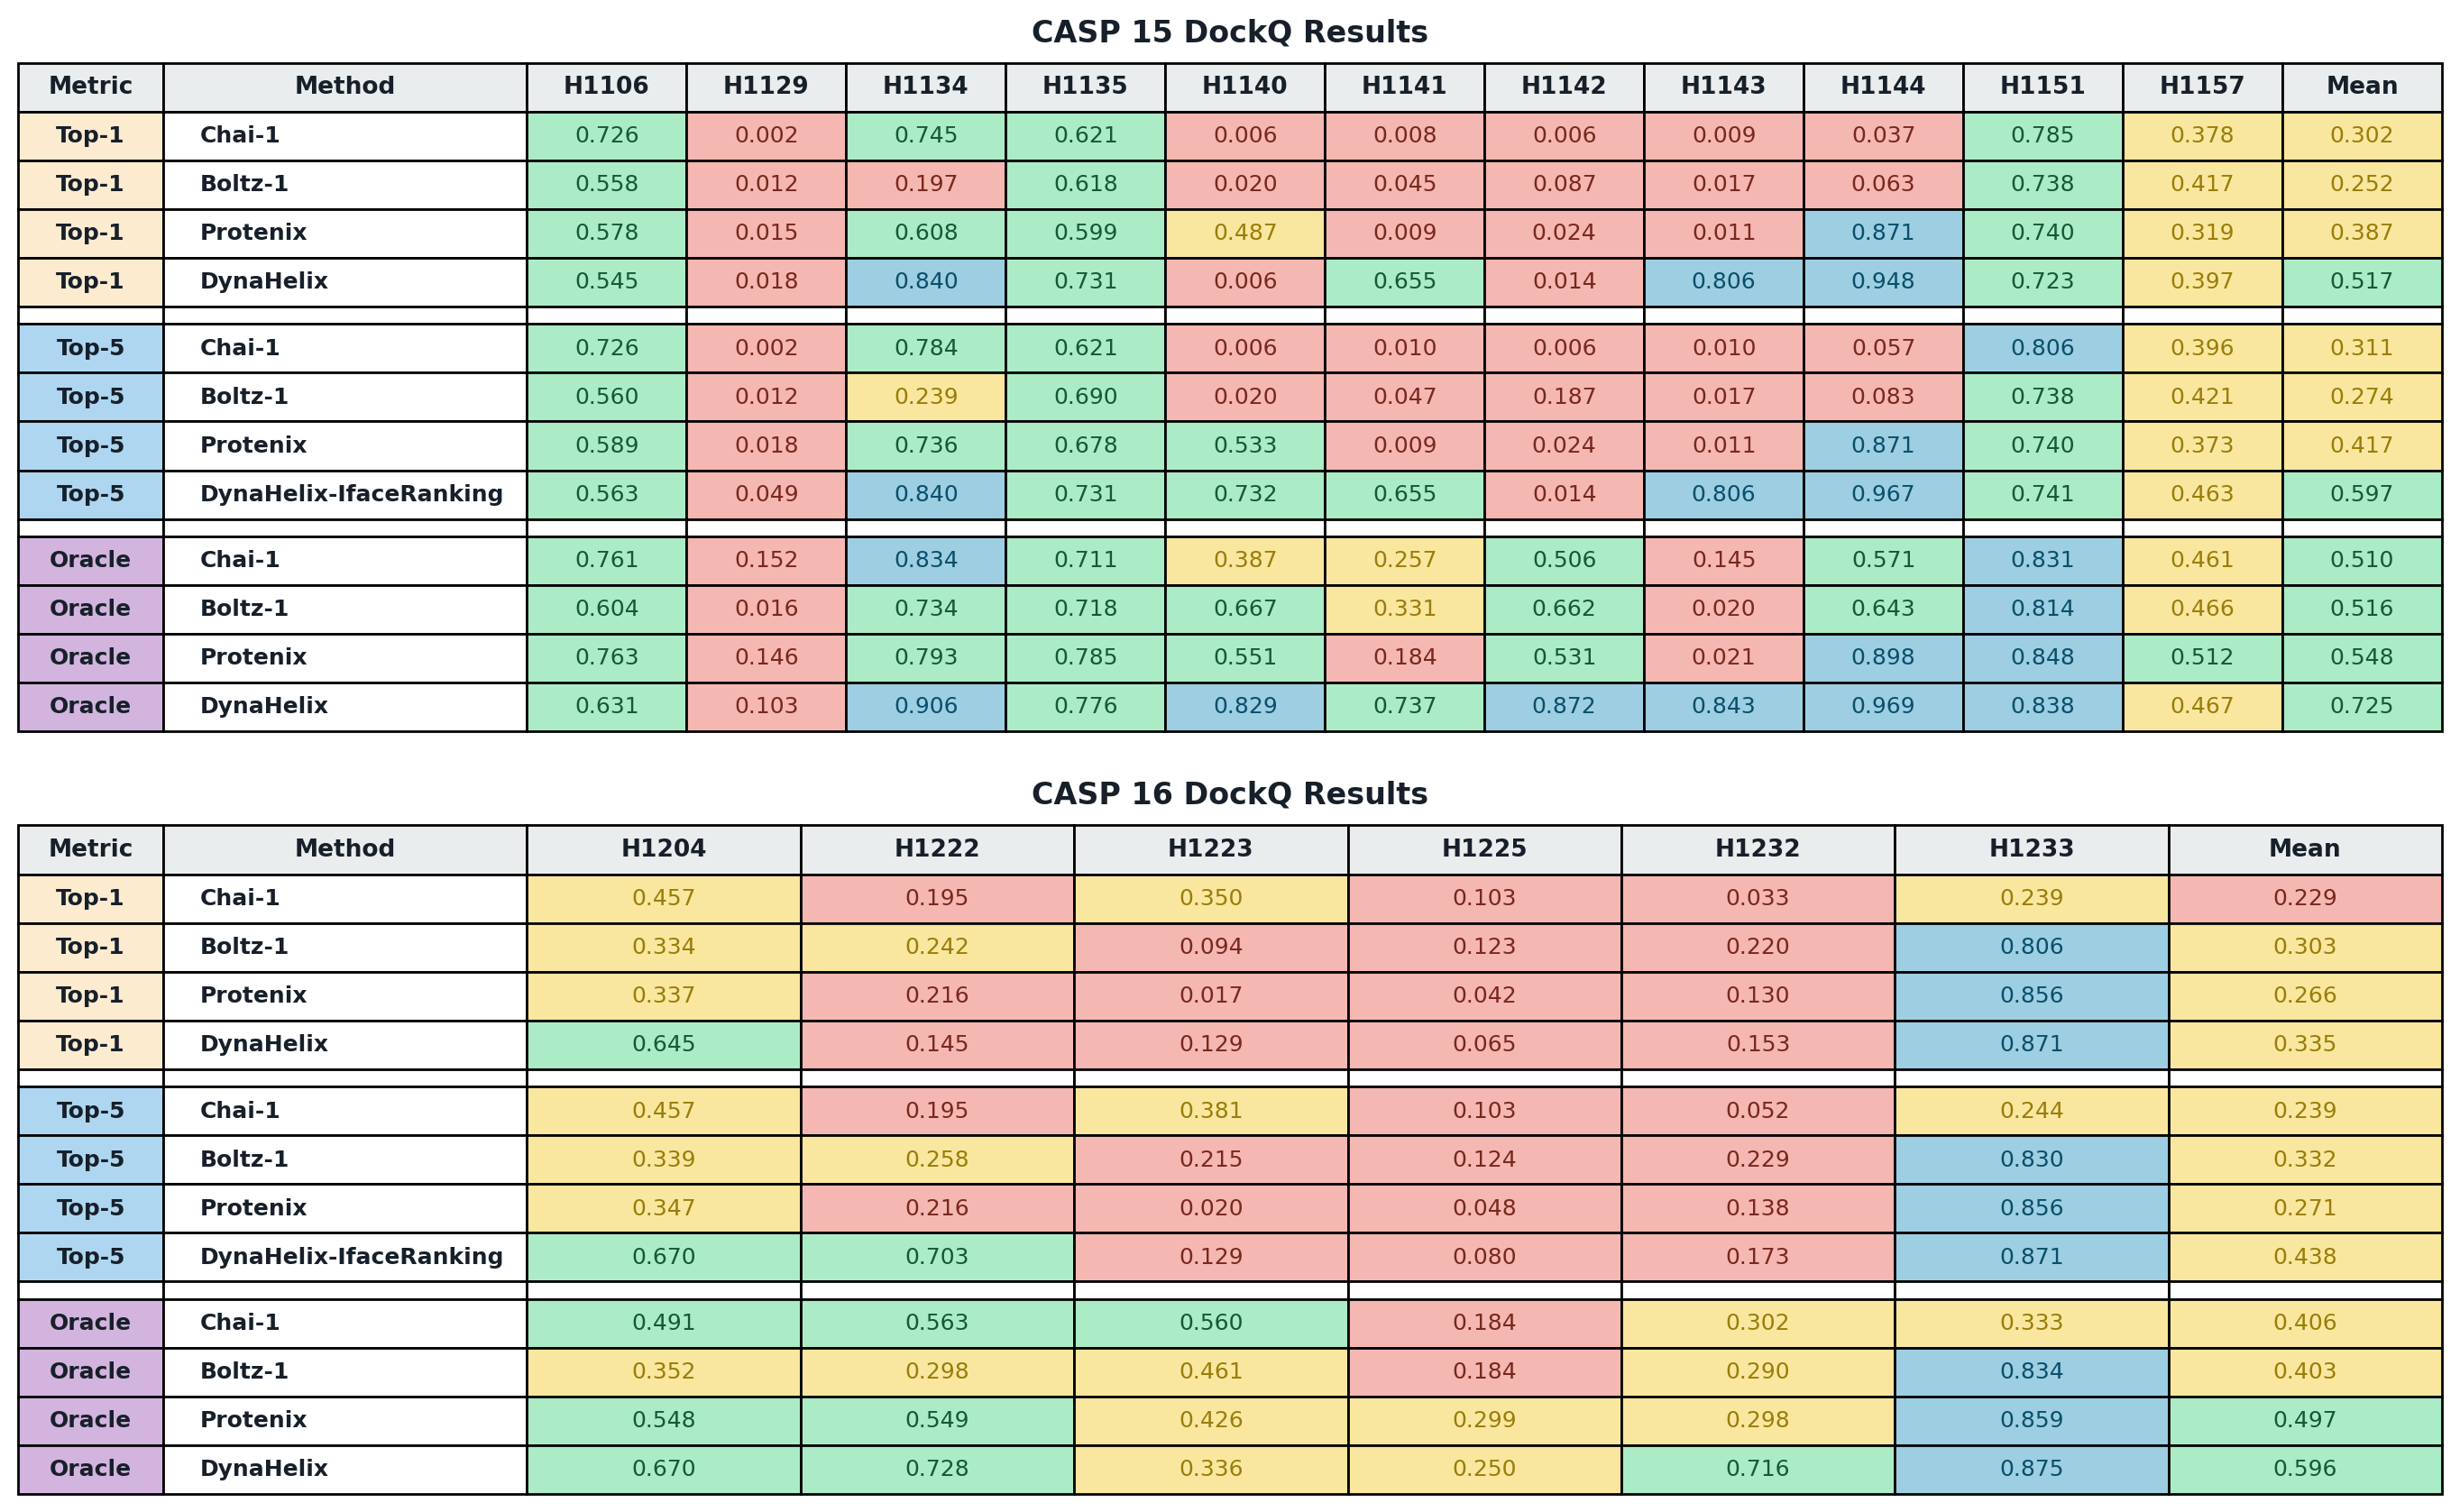

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. 樣式配置 (Style Config)
# ==========================================
COLORS = {
    "high": "#9dcee2",  # Light Blue (High)
    "med": "#ABEBC6",  # Light Green (Medium)
    "low": "#F9E79F",  # Light Yellow (Low)
    "fail": "#F5B7B1",  # Light Red (Fail)
    "text": "#17202A",  # Dark Text (Default)
    "top1_bg": "#FDEBD0",  # [新增] Light Orange/Peach for Top-1 Column
    "top5_bg": "#AED6F1",  # Light Blue for Top-5 Column
    "oracle_bg": "#D2B4DE",  # Light Purple for Oracle Column
    "method_bg": "#FFFFFF",  # Method BG
    "header_bg": "#EAEDED",  # Header Background
    "spacer_bg": "#FFFFFF",  # White spacer
}

# 文字顏色配置 (比底色更深的色號)
SCORE_TEXT_COLORS = {
    "high": "#0A4F6B",  # 深藍色 (對應 High 底色)
    "med": "#145A32",  # 深綠色 (對應 Med 底色)
    "low": "#9A7D0A",  # 深金色 (對應 Low 底色)
    "fail": "#78281F",  # 深紅色 (對應 Fail 底色)
    "default": "#17202A",  # 預設深灰
}

CUSTOM_METHOD_ORDER = [
    "Chai-1",
    "Boltz-1",
    "Protenix",
    "DynaHelix",
    "DynaHelix-IfaceRanking",
]


def get_score_color(val):
    if isinstance(val, str):
        return "white"
    try:
        v = float(val)
        if v >= 0.8:
            return COLORS["high"]
        elif 0.49 <= v < 0.8:
            return COLORS["med"]
        elif 0.23 <= v < 0.49:
            return COLORS["low"]
        elif v < 0.23:
            return COLORS["fail"]
    except (ValueError, TypeError):
        return "white"


# 獲取文字顏色的函數
def get_score_text_color(val):
    if isinstance(val, str):
        return SCORE_TEXT_COLORS["default"]
    try:
        v = float(val)
        if v >= 0.8:
            return SCORE_TEXT_COLORS["high"]
        elif 0.49 <= v < 0.8:
            return SCORE_TEXT_COLORS["med"]
        elif 0.23 <= v < 0.49:
            return SCORE_TEXT_COLORS["low"]
        elif v < 0.23:
            return SCORE_TEXT_COLORS["fail"]
    except (ValueError, TypeError):
        return SCORE_TEXT_COLORS["default"]
    return SCORE_TEXT_COLORS["default"]


# ==========================================
# 2. 數據結構重組 (Data Restructuring)
# ==========================================
def create_display_df(df_input, custom_order=None):
    # [修改] 篩選 Metric，加入 'Top-1'
    df_sub = df_input[df_input["Metric"].isin(["Top-1", "Top-5", "Oracle"])].copy()

    # 建立 Pivot Table
    pivot = df_sub.pivot_table(index=["Metric", "Method"], columns="PDB", values="Score")
    pivot["Mean"] = pivot.mean(axis=1)

    # [新增] 建立一個通用函數來提取指定 Metric 的數據，避免代碼重複
    def extract_metric_df(metric_name):
        if metric_name in pivot.index:
            df_raw = pivot.loc[metric_name]
            if custom_order:
                available = df_raw.index.tolist()
                valid_order = [m for m in custom_order if m in available]
                df_res = df_raw.reindex(valid_order).reset_index()
            else:
                df_res = df_raw.sort_index().reset_index()
            df_res.insert(0, "Metric", metric_name)
            return df_res
        return pd.DataFrame()

    # 依序提取 Top-1, Top-5, Oracle
    df_top1 = extract_metric_df("Top-1")
    df_top5 = extract_metric_df("Top-5")
    df_ora = extract_metric_df("Oracle")

    # [修改] 動態合併數據與插入 spacer (間隔行)
    dfs_to_concat = []
    columns_ref = None

    for d in [df_top1, df_top5, df_ora]:
        if not d.empty:
            if columns_ref is None:
                columns_ref = d.columns
            # 如果列表中已經有數據塊，則在加入新數據塊前先插入一個 spacer
            if dfs_to_concat:
                spacer = pd.DataFrame(columns=columns_ref)
                spacer.loc[0] = ["", ""] + [np.nan] * (len(columns_ref) - 2)
                dfs_to_concat.append(spacer)
            dfs_to_concat.append(d)

    if dfs_to_concat:
        final_df = pd.concat(dfs_to_concat, ignore_index=True)
    else:
        final_df = pd.DataFrame()

    return final_df


# ==========================================
# 3. 繪圖核心 (Compact Plotting)
# ==========================================
def draw_compact_table(ax, df_display, title):
    if df_display.empty:
        ax.axis("off")
        ax.text(0.5, 0.5, "No Data")
        return

    # --- 準備繪圖數據 ---
    cell_text = []
    cell_colors = []
    cell_text_colors = []

    for _, row in df_display.iterrows():
        row_txt = []
        row_col = []
        row_txt_col = []
        is_spacer = (row["Metric"] == "") and (row["Method"] == "")

        for col_idx, val in enumerate(row):
            # Column 0: Metric
            if col_idx == 0:
                row_txt.append(val)
                if val == "Top-1":
                    row_col.append(COLORS["top1_bg"])
                elif val == "Top-5":
                    row_col.append(COLORS["top5_bg"])
                elif val == "Oracle":
                    row_col.append(COLORS["oracle_bg"])
                else:
                    row_col.append("white")
                row_txt_col.append(SCORE_TEXT_COLORS["default"])

            # Column 1: Method
            elif col_idx == 1:
                row_txt.append(val)
                row_col.append(COLORS["method_bg"] if not is_spacer else "white")
                row_txt_col.append(SCORE_TEXT_COLORS["default"])

            # Column 2+: Scores
            else:
                if is_spacer or pd.isna(val):
                    row_txt.append("")
                    row_col.append("white")
                    row_txt_col.append(SCORE_TEXT_COLORS["default"])
                else:
                    row_txt.append(f"{val:.3f}")
                    row_col.append(get_score_color(val))
                    row_txt_col.append(get_score_text_color(val))

        cell_text.append(row_txt)
        cell_colors.append(row_col)
        cell_text_colors.append(row_txt_col)

    # --- 計算列寬 ---
    col_labels = df_display.columns.tolist()
    n_cols = len(col_labels)

    w_metric = 0.06
    w_method = 0.15
    if n_cols > 2:
        w_score = (1.0 - w_metric - w_method) / (n_cols - 2)
    else:
        w_score = 0.1

    col_widths = [w_metric, w_method] + [w_score] * (n_cols - 2)

    # --- 繪製表格 ---
    ax.axis("off")
    table = ax.table(
        cellText=cell_text,
        cellColours=cell_colors,
        colLabels=col_labels,
        colWidths=col_widths,
        loc="center",
        cellLoc="center",
    )

    # --- 樣式精修 ---
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.5)  # 稍微增大全局行高以防擁擠

    for (row, col), cell in table.get_celld().items():
        # Header (Row 0)
        if row == 0:
            cell.set_text_props(weight="bold", fontsize=9.5, color=COLORS["text"])
            cell.set_facecolor(COLORS["header_bg"])
            # [修復]: 刪除了 cell.set_height(0.08)，讓 table.scale 自動控制行高
            continue

        data_row_idx = row - 1

        # 應用文字顏色
        specific_text_color = cell_text_colors[data_row_idx][col]
        cell.set_text_props(color=specific_text_color)

        current_metric = df_display.iloc[data_row_idx]["Metric"]
        current_method = df_display.iloc[data_row_idx]["Method"]
        is_spacer = (current_metric == "") and (current_method == "")

        # Spacer Row
        if is_spacer:
            cell.set_height(0.03)
            continue

        # Metric Column (Col 0)
        if col == 0:
            cell.set_text_props(weight="bold", color=SCORE_TEXT_COLORS["default"])

        # Method Column (Col 1)
        if col == 1:
            cell.set_text_props(weight="bold", ha="left", color=SCORE_TEXT_COLORS["default"])

    # [修復]: 增加 pad (從 5 改為 15)，拉開 Title 與表頭的距離
    ax.set_title(title, pad=25, fontsize=12, fontweight="bold", color="#17202A")


# ==========================================
# 4. 主程序與佈局
# ==========================================

# 準備數據 (請確保外部已有 seed100_df 變量)
casp15_df = seed100_df[seed100_df["PDB"].str.startswith("H11")]
casp16_df = seed100_df[seed100_df["PDB"].str.startswith("H12")]

display_15 = create_display_df(casp15_df, custom_order=CUSTOM_METHOD_ORDER)
display_16 = create_display_df(casp16_df, custom_order=CUSTOM_METHOD_ORDER)

total_rows = len(display_15) + len(display_16)
fig_h = total_rows * 0.20 + 3.0

fig, axes = plt.subplots(2, 1, figsize=(14, fig_h), dpi=200)

draw_compact_table(axes[0], display_15, "CASP 15 DockQ Results")
draw_compact_table(axes[1], display_16, "CASP 16 DockQ Results")

# [修復]: 增加 hspace (從 0.15 改為 0.35)，拉開上下兩張表的距離
plt.subplots_adjust(left=0.02, right=0.98, top=0.92, bottom=0.05, hspace=0.3)
plt.savefig("./figs/fig5.png", bbox_inches="tight", dpi=300)
plt.savefig("./figs/fig5.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()